# AI for green extraction: a hands-on teaching example
**Dr. Abdul Bari Shah · KBTU**

Train a Random Forest to predict recovery from a hypothetical dried plant material.
**All 300 rows are simulated. No real plant species was tested.** Results demonstrate a workflow, not validated extraction conditions.

Run cells from top to bottom. In Colab select **Runtime → Run all**. For a live lesson, run one cell at a time using its play button.

We will: inspect data → hold out test rows → train → evaluate → predict → compare candidate conditions.

## 1. Load the tools
Colab normally includes these packages. For a local computer, install `requirements.txt` first.
The printed versions help explain small differences between computers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from pathlib import Path
from io import StringIO
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('scikit-learn:', sklearn.__version__)
print('NumPy:', np.__version__, '| pandas:', pd.__version__)

scikit-learn: 1.8.0
NumPy: 2.3.5 | pandas: 2.2.3


## 2. Where do the data come from?
In real research, we first conduct designed experiments and measure recovery. Here a deliberately invented equation generates the outcomes so anyone can practice without laboratory data.

| Column | Meaning | Simulated range |
|---|---|---|
| ethanol_pct | Ethanol in the initial ethanol–water solvent, % v/v | 20–80 |
| temperature_C | Extraction temperature, °C | 30–70 |
| time_min | Extraction time, minutes | 10–60 |
| solvent_mL_per_g | Initial solvent volume per gram of dry plant | 10–30 |
| recovery_pct | Recovered target compound / target compound initially present × 100 | Simulated outcome |

Recovery is **not** the percentage of the total plant mass extracted. In a real experiment, its denominator requires an independently justified measurement.

The synthetic equation has a solvent optimum near 60%, diminishing returns from time and solvent amount, a temperature effect, an interaction, and random noise. Its parameters are invented, not literature estimates. We show the equation openly below; the model receives only the input columns and simulated labels.

In [2]:
# Embedded copy of simulated_extraction_data.csv: no download or upload is needed.
SIMULATED_CSV = 'ethanol_pct,temperature_C,time_min,solvent_mL_per_g,recovery_pct\n66.4,61.2,33.9,19.4,78.82\n46.3,35.4,48.1,15.2,67.44\n71.5,51.4,55.2,10.9,77.9\n61.8,50.6,46.0,19.6,85.61\n25.7,64.3,58.2,29.2,65.76\n78.5,48.5,49.1,23.1,70.11\n65.7,45.4,53.3,19.9,77.76\n67.2,55.6,15.7,12.2,66.7\n27.7,40.7,46.6,15.0,56.48\n47.0,35.6,32.0,15.9,66.38\n42.2,49.1,37.7,25.3,70.68\n75.6,46.7,42.7,27.5,70.22\n58.6,39.3,58.5,28.0,80.7\n69.4,44.7,59.2,29.7,80.31\n46.6,44.7,24.4,29.6,72.88\n33.6,43.1,46.7,29.1,65.24\n53.3,45.2,47.5,11.4,72.19\n23.8,57.4,27.3,12.8,56.73\n69.7,41.9,16.2,16.1,66.85\n57.9,68.0,12.0,21.1,77.05\n65.5,66.7,48.9,11.9,80.02\n41.3,49.2,34.5,26.9,67.12\n78.2,43.1,59.3,22.3,69.56\n73.6,51.4,33.2,20.8,74.08\n66.7,63.9,58.9,13.3,82.46\n31.7,56.1,30.6,15.1,59.49\n48.0,62.2,49.7,13.2,79.19\n22.6,51.3,14.2,27.0,56.31\n29.3,55.3,37.8,21.7,61.79\n61.0,41.5,50.1,24.7,83.22\n64.7,59.4,56.2,15.9,86.54\n78.1,38.1,51.1,17.4,70.85\n39.5,57.8,11.8,18.1,58.22\n42.2,64.4,28.6,25.2,70.05\n48.2,35.3,12.4,25.4,69.87\n31.4,54.6,15.5,14.1,52.12\n27.8,33.8,43.8,28.8,56.4\n48.5,59.0,45.7,12.4,74.01\n33.6,33.4,48.7,27.9,62.87\n60.2,67.4,53.3,12.0,81.75\n46.2,35.5,47.0,15.3,67.76\n70.0,68.4,50.0,26.9,81.19\n62.0,62.0,12.4,13.6,71.8\n38.7,53.7,21.7,18.3,61.44\n69.9,61.3,41.1,19.0,83.98\n68.3,61.8,52.9,14.9,80.9\n43.2,67.8,10.2,24.2,67.11\n37.3,40.1,35.7,27.0,63.72\n60.9,53.6,43.9,27.5,84.24\n28.4,33.8,11.5,16.8,47.16\n32.0,54.6,30.1,20.6,56.43\n20.4,36.9,54.8,15.0,51.71\n67.2,52.6,43.6,14.9,74.33\n59.9,52.9,21.9,13.2,70.76\n62.3,48.6,52.6,28.8,81.83\n66.8,50.9,27.4,27.8,81.78\n47.5,60.6,52.7,25.5,80.14\n54.1,62.0,24.9,20.4,81.98\n28.4,49.7,39.5,19.8,61.14\n26.9,54.0,29.8,20.6,60.85\n60.1,67.2,23.7,20.7,78.86\n48.3,34.8,54.3,18.7,73.73\n53.9,34.7,19.4,12.6,70.21\n65.9,33.5,14.2,12.5,65.57\n58.1,56.3,27.1,29.0,83.5\n53.2,46.7,45.9,19.6,80.18\n53.6,61.0,50.4,29.1,84.32\n38.2,56.8,59.9,13.3,64.72\n21.8,43.3,24.8,21.1,52.35\n46.2,65.9,30.4,14.2,72.25\n32.9,60.5,16.8,15.1,57.89\n44.5,40.8,38.7,10.6,63.47\n71.2,44.6,59.9,12.4,72.83\n34.0,42.6,45.0,28.3,65.4\n23.5,36.3,39.8,16.4,55.68\n36.9,35.9,29.6,22.2,64.47\n37.6,67.4,55.8,19.3,72.83\n59.7,47.5,34.8,18.0,77.4\n53.4,45.3,16.7,20.6,76.56\n67.0,59.2,28.3,13.7,75.2\n59.9,52.1,13.4,29.8,79.32\n44.4,67.4,20.1,26.4,71.52\n68.8,61.2,10.9,24.8,72.37\n30.0,49.2,32.7,19.4,56.06\n21.4,45.1,41.7,13.1,54.2\n25.4,69.5,27.2,28.4,57.87\n63.3,58.7,31.0,16.8,82.02\n47.7,68.0,58.0,11.0,78.23\n29.7,34.7,47.6,16.8,55.43\n50.1,64.0,37.0,25.9,81.53\n29.1,55.5,24.2,22.5,58.15\n61.8,34.9,54.8,25.0,79.05\n46.8,53.5,21.8,25.9,74.25\n42.9,57.4,26.3,14.2,67.01\n38.1,30.5,55.5,28.5,68.44\n57.8,48.2,36.5,18.8,78.94\n41.7,63.0,47.1,22.8,76.01\n25.3,41.8,39.5,10.0,52.51\n27.1,48.3,42.7,29.9,63.82\n77.7,47.7,25.0,15.6,64.03\n74.5,42.1,22.1,11.2,63.33\n62.0,66.7,26.1,19.2,80.5\n36.0,61.3,17.8,12.6,56.72\n78.2,34.4,53.7,13.0,65.18\n66.7,69.9,24.2,22.6,79.94\n63.0,65.2,38.1,17.9,83.92\n47.0,41.4,49.6,28.4,78.43\n36.3,63.5,49.2,16.4,70.45\n25.8,34.3,31.9,24.5,55.44\n74.2,70.0,33.8,19.2,74.67\n47.3,56.6,59.7,23.2,77.8\n32.1,56.0,43.7,22.0,64.79\n38.4,33.6,50.7,19.5,62.36\n54.8,65.9,55.1,29.0,90.11\n30.6,31.2,49.4,16.9,57.48\n71.4,39.6,19.3,13.5,65.9\n65.5,35.7,38.1,23.6,79.96\n63.2,61.1,15.1,26.9,74.3\n45.9,37.9,42.6,10.8,62.25\n57.6,66.4,57.8,19.0,87.23\n55.0,56.3,35.6,27.8,83.04\n59.0,31.4,31.6,25.0,77.94\n25.1,30.2,11.8,29.8,47.76\n44.9,32.1,58.0,20.6,69.64\n22.5,54.2,15.2,23.2,58.42\n49.6,62.1,12.1,16.0,71.37\n39.8,39.5,22.3,29.0,64.55\n28.7,64.0,13.3,17.3,54.03\n26.2,32.3,32.8,24.8,55.3\n55.3,62.0,35.8,18.1,77.39\n30.2,67.1,25.6,21.2,61.74\n75.5,60.9,12.5,24.4,69.71\n54.9,57.9,15.6,20.2,72.68\n40.8,63.5,29.2,28.1,70.01\n55.5,31.6,13.0,18.4,67.15\n21.4,38.1,44.9,22.9,55.28\n77.5,35.0,20.4,16.8,61.95\n48.9,50.2,25.1,18.2,68.47\n67.0,59.8,29.7,18.8,80.29\n25.0,55.2,30.8,12.5,56.99\n49.2,64.0,10.1,11.8,65.56\n49.4,36.2,15.6,23.3,63.95\n76.3,59.4,53.1,23.1,73.9\n54.3,37.7,10.1,23.3,72.67\n48.4,40.8,35.4,10.4,62.46\n36.0,58.4,34.5,16.5,63.73\n39.9,69.2,26.7,14.0,62.35\n51.2,54.5,31.6,25.6,80.63\n46.3,32.2,49.0,27.2,70.88\n21.3,54.7,52.1,14.9,59.64\n69.6,31.7,23.0,23.4,72.35\n73.8,65.4,26.1,12.6,73.78\n28.4,58.4,22.1,15.5,56.29\n53.2,36.9,34.0,12.8,72.96\n26.5,33.7,44.2,15.7,51.81\n60.3,37.3,21.4,23.5,78.46\n36.9,69.2,26.5,28.2,65.27\n59.6,48.3,56.5,14.1,78.9\n63.6,61.4,12.4,20.8,75.77\n66.1,55.5,33.0,24.0,77.8\n26.5,52.9,45.6,29.1,63.76\n75.0,35.8,17.5,22.2,67.22\n33.8,67.8,12.4,15.1,56.27\n22.2,42.1,16.9,22.5,49.36\n53.3,53.1,55.9,16.4,79.98\n42.3,58.0,10.5,29.5,66.91\n69.8,56.0,19.4,18.0,69.3\n68.5,67.6,11.6,23.7,71.12\n39.0,35.9,15.5,10.5,55.39\n77.2,50.3,41.0,18.0,70.5\n37.5,46.2,22.1,27.5,64.16\n50.9,49.0,38.5,22.2,81.65\n35.4,34.8,39.5,18.9,61.37\n76.2,35.4,52.5,28.7,72.45\n29.9,41.1,10.2,27.1,58.37\n22.7,42.2,52.7,16.4,56.34\n46.1,47.1,41.0,20.9,71.73\n79.5,54.4,18.1,19.8,65.06\n73.5,55.4,48.6,22.6,77.85\n64.9,46.5,52.8,16.7,78.4\n73.4,46.4,22.7,14.9,65.63\n73.6,38.7,55.9,28.3,79.11\n51.1,53.5,32.7,28.5,80.14\n39.0,42.7,40.2,26.9,65.77\n66.3,31.4,59.2,29.6,80.51\n59.7,46.7,28.1,24.9,79.8\n42.4,49.0,50.7,25.3,71.93\n25.7,39.0,25.9,25.3,57.25\n64.8,52.9,50.0,19.6,79.41\n35.7,52.6,40.0,19.1,65.54\n76.2,58.1,20.8,14.8,70.6\n34.5,55.9,30.7,22.9,65.24\n27.4,56.1,25.9,15.8,56.33\n69.9,42.6,13.9,15.2,66.06\n29.2,61.5,11.5,21.7,54.85\n30.8,52.0,27.3,18.2,58.57\n56.0,47.3,11.0,14.4,69.06\n72.5,55.0,18.3,26.3,74.37\n31.8,44.4,46.3,27.2,59.85\n38.6,50.5,45.4,13.4,66.32\n66.6,59.5,46.9,10.2,76.63\n78.3,65.5,25.9,16.7,68.77\n50.0,66.8,54.5,26.0,80.79\n28.6,50.1,39.7,26.8,64.97\n20.8,50.8,16.3,12.8,52.16\n33.8,62.0,17.2,25.5,63.56\n27.9,42.6,44.7,12.3,52.5\n60.7,63.5,18.6,17.8,79.8\n27.3,49.8,35.4,30.0,62.46\n50.4,34.6,59.6,13.9,69.17\n61.7,32.9,10.2,13.1,66.68\n54.9,63.7,10.8,18.5,74.45\n32.0,32.2,59.7,22.4,61.17\n68.2,41.2,39.2,28.7,78.67\n62.9,43.4,16.3,29.6,76.93\n64.3,36.9,54.9,11.4,77.45\n27.9,42.6,54.0,12.8,59.0\n27.4,59.7,36.8,25.8,57.65\n75.7,30.6,41.1,15.4,65.07\n43.9,63.1,23.7,27.7,72.28\n38.1,64.3,12.5,23.3,58.73\n49.3,44.9,39.7,12.2,71.73\n59.8,36.1,24.7,26.7,79.91\n77.3,54.0,43.2,13.5,66.67\n37.2,34.8,51.8,18.5,63.27\n75.5,44.6,10.9,21.0,61.54\n21.5,68.3,39.8,20.0,59.66\n53.3,69.8,21.6,23.7,81.07\n58.0,60.9,53.7,23.1,85.16\n26.4,42.4,22.7,29.8,57.94\n28.4,57.5,40.5,30.0,60.82\n45.1,58.2,37.7,20.3,77.98\n78.0,45.5,29.8,11.9,64.42\n55.8,55.6,43.9,24.6,83.31\n76.0,30.4,46.3,29.5,71.01\n68.3,38.4,38.3,16.4,71.21\n48.0,51.0,47.9,19.2,78.5\n67.1,36.6,59.2,18.5,76.15\n21.1,36.6,31.0,11.0,49.29\n26.5,63.5,35.7,23.4,61.88\n69.8,69.6,10.6,17.1,67.94\n67.8,52.2,49.8,25.7,83.12\n34.0,63.6,36.0,26.6,67.72\n51.8,69.6,30.4,26.4,81.58\n56.4,35.7,14.7,18.3,71.22\n72.1,47.9,54.5,16.4,75.71\n56.2,45.7,29.8,25.0,78.66\n44.8,33.2,44.1,26.0,74.95\n42.5,60.2,17.5,19.8,63.77\n45.6,47.4,58.1,27.9,78.53\n59.1,48.8,18.9,12.9,75.99\n72.0,36.0,20.0,27.6,68.39\n47.2,37.2,52.9,11.9,73.28\n34.9,66.3,55.6,13.1,67.49\n34.2,31.8,20.6,20.7,57.98\n64.8,39.3,33.5,11.4,72.87\n69.0,41.7,46.7,11.1,71.71\n26.3,49.6,53.9,10.0,55.4\n24.0,53.5,29.0,18.7,58.28\n55.7,49.7,35.9,25.5,84.18\n28.8,33.4,47.1,10.7,53.18\n69.5,39.7,46.6,23.0,74.75\n38.6,63.7,49.1,26.5,74.08\n28.6,55.5,38.5,13.4,60.53\n75.3,56.0,15.2,12.9,65.37\n29.9,56.8,55.2,27.2,67.63\n37.1,60.5,53.3,26.5,70.66\n29.2,32.3,49.9,20.8,55.99\n26.9,44.7,15.0,26.4,52.71\n21.3,51.6,20.2,11.9,47.47\n23.3,43.5,47.2,17.9,57.92\n30.5,63.8,11.2,24.8,56.85\n23.2,49.3,59.0,15.1,57.54\n55.5,60.7,28.9,25.0,76.26\n60.8,64.1,46.0,20.1,82.6\n43.6,50.2,54.4,25.0,76.3\n39.1,66.4,29.7,19.3,66.33\n50.3,53.5,26.0,17.4,75.1\n72.5,64.0,40.4,14.4,72.53\n71.1,43.6,39.0,14.2,74.87\n22.6,50.0,30.5,25.0,58.3\n30.9,51.3,40.1,12.4,58.98\n34.2,34.2,56.8,11.7,61.72\n35.0,45.9,33.4,13.5,62.3\n54.3,66.7,19.8,13.5,74.16\n45.0,55.2,28.9,26.5,72.21\n23.0,37.1,29.7,18.0,53.03\n42.4,43.6,16.6,29.8,66.62\n51.4,37.7,18.1,12.7,67.14\n26.1,31.0,44.2,23.1,55.87\n70.0,67.1,27.0,19.0,79.5\n23.1,47.9,57.7,17.9,58.99\n75.5,42.3,22.2,27.5,73.36\n25.9,53.9,14.9,29.5,56.52\n70.6,30.3,47.7,27.5,78.06\n74.2,41.1,54.1,13.8,70.44\n78.8,58.1,23.9,14.4,67.06\n68.1,55.4,20.1,23.1,74.65\n66.8,69.3,19.3,15.8,72.93\n58.5,54.8,36.1,24.7,84.07\n'
data = pd.read_csv(StringIO(SIMULATED_CSV))
print('SIMULATED teaching data:', data.shape)
print(data.head().to_string(index=False))

SIMULATED teaching data: (300, 5)
 ethanol_pct  temperature_C  time_min  solvent_mL_per_g  recovery_pct
        66.4           61.2      33.9              19.4         78.82
        46.3           35.4      48.1              15.2         67.44
        71.5           51.4      55.2              10.9         77.90
        61.8           50.6      46.0              19.6         85.61
        25.7           64.3      58.2              29.2         65.76


### Optional: inspect or regenerate the synthetic dataset
This function documents exactly how the CSV was produced. It does not replace the loaded dataset unless you explicitly assign its result to `data`.

In [3]:
def make_simulated_data(n=300, seed=42):
    rng = np.random.default_rng(seed)
    ethanol = rng.uniform(20, 80, n).round(1)
    temperature = rng.uniform(30, 70, n).round(1)
    time = rng.uniform(10, 60, n).round(1)
    ratio = rng.uniform(10, 30, n).round(1)
    recovery = (28 + 24*np.exp(-((ethanol-60)/22)**2)
                + 18*(1-np.exp(-time/22))
                + 14*(1-np.exp(-(ratio-5)/12))
                + 0.22*(temperature-30)
                - 0.025*np.maximum(temperature-60, 0)**2
                + 0.04*(temperature-50)*(time-35)/25
                + rng.normal(0, 2, n))
    return pd.DataFrame({'ethanol_pct': ethanol, 'temperature_C': temperature,
                         'time_min': time, 'solvent_mL_per_g': ratio,
                         'recovery_pct': np.clip(recovery, 0, 100).round(2)})

## 3. Inspect the observations
Each dot represents one simulated experiment. The scatter also reflects differences in the other three inputs, so this plot alone cannot establish the effect of ethanol.

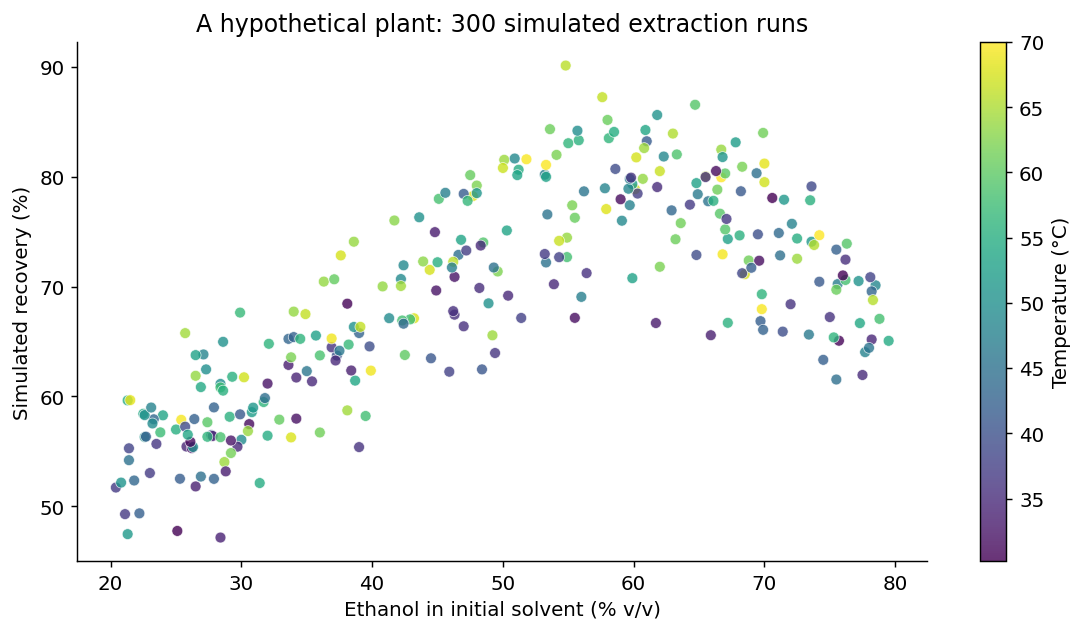

In [4]:
assert data.shape == (300, 5)
assert not data.isna().any().any()
assert data['recovery_pct'].between(0, 100).all()
fig, ax = plt.subplots()
dots = ax.scatter(data.ethanol_pct, data.recovery_pct, c=data.temperature_C,
                  cmap='viridis', alpha=0.8, edgecolors='white', linewidths=0.4)
fig.colorbar(dots, ax=ax, label='Temperature (°C)')
ax.set(xlabel='Ethanol in initial solvent (% v/v)', ylabel='Simulated recovery (%)',
       title='A hypothetical plant: 300 simulated extraction runs')
plt.tight_layout()
plt.show()

## 4. Hold back 20% before training
**X** contains the conditions; **y** contains the known recovery. We train on 240 rows and reserve 60 rows for one final evaluation. The model cannot see their recovery during training.

A random split is appropriate for these independently generated rows. With real plant data, keep related replicates and batches together using group-based splitting. This demo fixes the model settings in advance; if tuning them, use cross-validation within the training set, never the held-out test set.

In [5]:
features = ['ethanol_pct', 'temperature_C', 'time_min', 'solvent_mL_per_g']
X, y = data[features], data['recovery_pct']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)
assert set(X_train.index).isdisjoint(X_test.index)
print(f'Training rows: {len(X_train)}; held-out test rows: {len(X_test)}')

Training rows: 240; held-out test rows: 60


## 5. Train a Random Forest
The forest averages predictions from 200 decision trees. Bootstrap sampling gives trees different training samples; `max_features=0.75` makes each split consider a random subset of three of our four inputs. `min_samples_leaf=3` reduces very small leaves.

We also train a simple baseline that always predicts the average training recovery. A useful model should improve on that baseline.

In [6]:
model = RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                              max_features=0.75, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)
baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)
print('Both models trained using only the training rows.')

Both models trained using only the training rows.


## 6. Evaluate once on the held-out data
MAE is the average absolute error in **percentage points**. RMSE penalizes larger errors more strongly. R² compares squared errors with predicting the test-set mean and can be negative.

Good results here mean learning this artificial pattern, not proving performance in a laboratory. Do not repeatedly change settings after seeing test results.

        Model  MAE (percentage points)  RMSE (percentage points)     R²
Mean baseline                    7.753                     9.272 -0.005
Random Forest                    2.499                     3.138  0.885


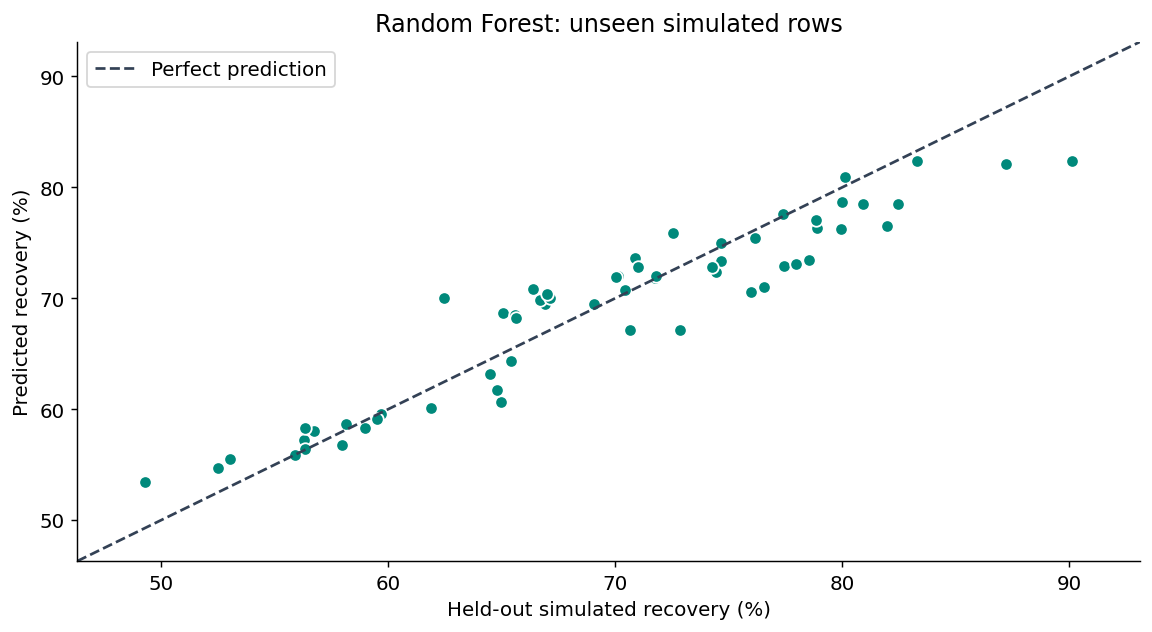

In [7]:
predicted = model.predict(X_test)
rows = []
for name, fitted in [('Mean baseline', baseline), ('Random Forest', model)]:
    p = fitted.predict(X_test)
    rows.append({'Model': name, 'MAE (percentage points)': mean_absolute_error(y_test, p),
                 'RMSE (percentage points)': np.sqrt(mean_squared_error(y_test, p)),
                 'R²': r2_score(y_test, p)})
metrics = pd.DataFrame(rows)
print(metrics.round(3).to_string(index=False))
fig, ax = plt.subplots()
ax.scatter(y_test, predicted, color='#00897b', s=48, edgecolors='white')
lo, hi = min(y_test.min(), predicted.min())-3, max(y_test.max(), predicted.max())+3
ax.plot([lo, hi], [lo, hi], '--', color='#334155', label='Perfect prediction')
ax.set(xlabel='Held-out simulated recovery (%)', ylabel='Predicted recovery (%)',
       title='Random Forest: unseen simulated rows', xlim=(lo,hi), ylim=(lo,hi))
ax.legend()
plt.tight_layout()
plt.show()

## 7. Try your own extraction conditions
Your lecture example is **70% ethanol, 65°C, 50 minutes**. We must also supply the fourth input: here we assume **20 mL solvent per gram of dry plant**.

Edit the four numbers below and rerun this cell. The guard keeps inputs within the training ranges, but being within those ranges does not establish laboratory validity. This prediction is not a measured recovery and need not equal the illustrative numbers on the slides.

In [8]:
new_condition = pd.DataFrame([{'ethanol_pct': 70, 'temperature_C': 65,
                               'time_min': 50, 'solvent_mL_per_g': 20}])[features]
if ((new_condition.iloc[0] < X_train.min()) | (new_condition.iloc[0] > X_train.max())).any():
    raise ValueError('Choose values within the observed training ranges:\n' + str(X_train.agg(['min','max'])))
print(new_condition.to_string(index=False))
print(f'Predicted recovery: {model.predict(new_condition)[0]:.1f}% (teaching simulation only)')

 ethanol_pct  temperature_C  time_min  solvent_mL_per_g
          70             65        50                20
Predicted recovery: 80.3% (teaching simulation only)


## 8. Compare candidate conditions
Prediction answers “what recovery might we obtain?” A search compares many predictions under stated constraints.

We search a small grid inside the training ranges. For a transparent classroom comparison, define an **arbitrary heating-effort index** = (temperature − 25) × time × solvent ratio / 1000. This is NOT measured energy, kWh, cost, or carbon emissions. It omits heat loss, equipment, solvent recovery, and many other processes.

We compare recovery with that index. A candidate is dominated if another has at least as much predicted recovery and no more heating effort, with one strict improvement. Non-dominated points are trade-offs, not guaranteed real optima.

Lowest effort candidates meeting the teaching requirement:
 ethanol_pct  temperature_C  time_min  solvent_mL_per_g  predicted_recovery_pct  heating_effort_index  non_dominated
          60             35        25                24                   76.12                   6.0           True
          60             35        35                18                   75.10                   6.3          False
          60             35        25                28                   76.59                   7.0           True
          60             35        45                18                   75.32                   8.1          False
          60             35        35                24                   78.82                   8.4           True
These are candidates for experimental validation, not lab recommendations.


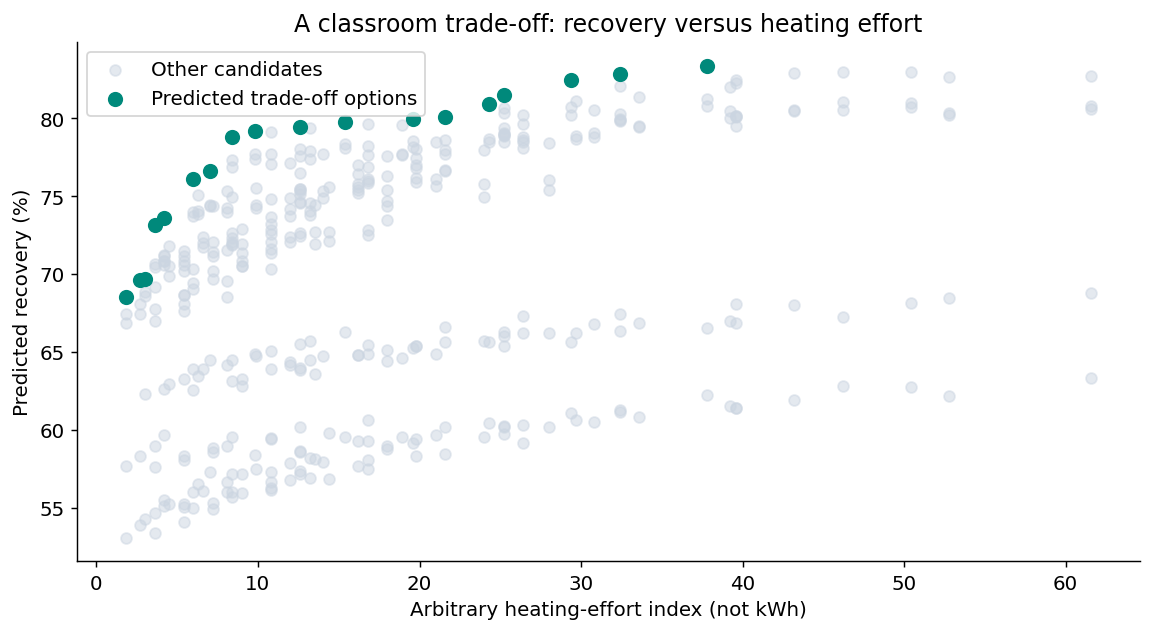

In [9]:
from itertools import product
candidates = pd.DataFrame(product([30,40,50,60,70], [35,45,55,65],
                                  [15,25,35,45,55], [12,18,24,28]), columns=features)
candidates['predicted_recovery_pct'] = model.predict(candidates[features])
candidates['heating_effort_index'] = ((candidates.temperature_C-25)*candidates.time_min
                                      *candidates.solvent_mL_per_g/1000)
recovery = candidates.predicted_recovery_pct.to_numpy()
effort = candidates.heating_effort_index.to_numpy()
pareto = np.array([not np.any((recovery >= recovery[i]) & (effort <= effort[i]) &
                              ((recovery > recovery[i]) | (effort < effort[i])))
                   for i in range(len(candidates))])
candidates['non_dominated'] = pareto
fig, ax = plt.subplots()
ax.scatter(effort[~pareto], recovery[~pareto], color='#cbd5e1', alpha=0.5, label='Other candidates')
ax.scatter(effort[pareto], recovery[pareto], color='#00897b', s=55, label='Predicted trade-off options')
ax.set(xlabel='Arbitrary heating-effort index (not kWh)', ylabel='Predicted recovery (%)',
       title='A classroom trade-off: recovery versus heating effort')
ax.legend()
plt.tight_layout()
plt.show()

# This minimum recovery is a teaching choice, not a product specification.
minimum_recovery = 75
eligible = candidates[candidates.predicted_recovery_pct >= minimum_recovery]
if eligible.empty:
    print('No candidate meets the selected recovery requirement.')
else:
    shortlist = eligible.sort_values(['heating_effort_index','predicted_recovery_pct'],
                                     ascending=[True,False]).head(5)
    print('Lowest effort candidates meeting the teaching requirement:')
    print(shortlist.round(2).to_string(index=False))
print('These are candidates for experimental validation, not lab recommendations.')

## 9. Student exercise and discussion
1. Predict recovery at 50% ethanol, 45°C, 30 minutes, and 15 mL/g.
2. Change only time to 50 minutes. How does the prediction change?
3. Change `minimum_recovery` from 75 to 80 and rerun the candidate-search cell. Does the lowest eligible heating effort change?
4. Why is the highest predicted recovery not automatically the greenest process?
5. What actual measurements would you need to claim a carbon reduction?

**Answers to discuss:** a one-input change explores the fitted model, not causality. A higher recovery requirement cannot lower the minimum feasible effort on the same grid. Carbon claims require a consistent functional unit and boundary, actual energy/material inventories, appropriate emission factors, and product quality/recovery information.

## 10. How to move to real research
Replace simulated rows with measured experimental data. Specify species, plant part, moisture, particle size, batches, analytical method, target compound and recovery denominator. Design experiments, include replicates, group related observations when splitting, compare baselines and tune only within training data. Confirm selected conditions with independent laboratory experiments. Measure energy, solvent losses and quality before making sustainability claims.

The RF does not understand chemistry, extrapolate reliably, or supply calibrated uncertainty just by having many trees. This notebook does not establish an optimum for any real plant.

## References and documentation
- [RandomForestRegressor — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html)
- [Avoiding data leakage — scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html)
- [Cross-validation — scikit-learn](https://scikit-learn.org/stable/modules/cross_validation.html)
- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html)